In [1]:
import xarray as xr 
import numpy as np
from glob import glob
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import cm
import matplotlib.pyplot as plt

from cmcrameri import cm as cmcra
import plotting_utils
plotting_utils.mk_binary_alpha()

In [2]:
def get_files(path_source, exp, folders, grid):
    """Return sorted file paths for the given experiment, folders, and grid."""
    path = Path(path_source) / exp

    files = sorted(
        f
        for folder in folders
        for f in (path / folder).glob(f"*1y*{grid}.nc")
    )
    return files


In [9]:
# importing processed dataset
path_source = Path('../steady_out/') 

exp = 'TEMP'
ds_NS = xr.open_dataset(path_source / f"{exp}.nc")
ds_NS_steady = ds_NS.sel(T0=1)

exp = 'FSLIP'
ds_FS_steady = xr.open_dataset(path_source / f"{exp}.nc")


path_source = Path('../monthly_out/')

exp = 'FSLIP_m'
ds_FS_monthly = xr.open_dataset(path_source / f"{exp}.nc")

In [12]:
# Importing raw dataset

path_source = Path('../raw_yearly_out/') 
exp =  'FSLIP_wtc'


years = ["0108", "0109", "0110"]

# Import experiment
dsT, dsU, dsV, dsW = [
    xr.open_mfdataset(
        get_files(path_source, exp, years, grid),
        combine="by_coords",
    )
    for grid in ["T", "U", "V", "W"]
]

print(f"Imported {exp}")


Imported FSLIP_wtc


In [13]:
# Useful functions

def clean_T(ds):
    ds = ds.isel(x=slice(1,127), y=slice(1,27), deptht=slice(0,30))
    return ds

def get_u_depth_mean_on_T(ds):
    U = ds.vozocrtx.where(ds.vozocrtx != 0) #mask over land
    U = U.mean(dim='depthu')
    U = (U.values[:,:,1:] + U.values[:,:,:-1])/2
    U = U[:,1:,:]
    return U

def get_v_depth_mean_on_T(ds):
    V = ds.vomecrty.where(ds.vomecrty != 0) #mask over land
    V = V.mean(dim='depthv')
    V = (V.values[:,1:,:] + V.values[:,:-1,:])/2
    V = V[:,:,1:]
    return V

def get_bsf_on_T(BSF):
    bsf = (BSF[1:] + BSF[:-1])/2
    return bsf


In [14]:
# define grid coordinates

# meridional
x_T = np.arange(1,251+1,2)
x_U = np.arange(0,252+1,2)

# zonal
y_T = np.arange(1,51+1,2)
y_V = np.arange(0,52+1,2)

# depth
z_T = np.arange(10,590+1,20)
z_W = np.arange(0,600+1,20)

# Basal melt rates

In [18]:
# define lists
sfx_list = np.arange(0, 0.1+0.001, 0.005) # g/m^2/s

colors_plot =  ['tab:blue','tab:orange']

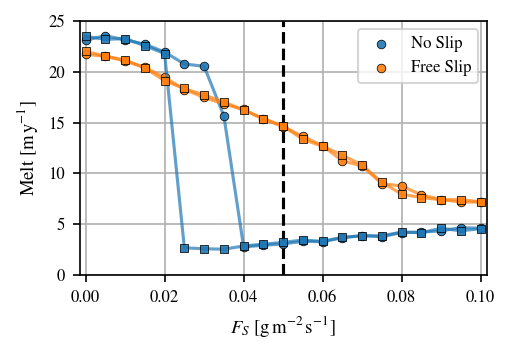

In [24]:
datasets = [
    (ds_NS_steady.melt_0D, colors_plot[0], "No Slip"),
    (ds_FS_steady.melt_0D, colors_plot[1], "Free Slip")
]

plt.figure(figsize=(3.5,2.2),dpi=150)

plt.vlines([0.05],0,25,colors='black', linestyle='dashed')

for i, marker in enumerate(['o', 's']):
    for data, color, label in datasets:

        y = data.isel(transition=i).values

        plt.plot(
            sfx_list, y,
            color=color, alpha=0.7
        )

        plt.scatter(
            sfx_list, y,
            marker=marker,
            edgecolors='black',
            facecolors=color,
            lw=0.4, s=17,
            alpha=0.9, zorder=2,
            label=label if i == 0 else None
        )



plt.xlabel(r'$F_S$ [$\mathrm{g\,m^{-2}\,s^{-1}}$]') 
plt.ylabel(r'Melt [$\mathrm{m\,y^{-1}}$]')


plt.xlim(0-0.0015,0.1+0.0015)
plt.ylim(0, 25)

#plt.yscale('log')

plt.grid()

plt.legend()

plt.savefig('./Figure10/FSLIP_melt.pdf', format='pdf', bbox_inches='tight')

plt.show()

# dzT

In [25]:
# define lists

time_list = np.linspace(0,210,210*12) # years

depth_list = np.arange(20, 580+1, 20) # m

dzT_resto = (1 - (-1.9))/600 # °C/m

TypeError: Dimensions of C (29, 1920, 2) should be one smaller than X(2520) and Y(29) while using shading='flat' see help(pcolormesh)

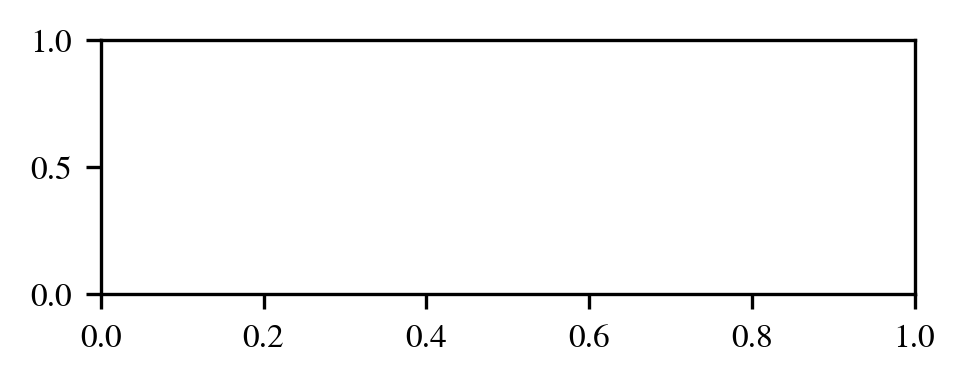

In [26]:
TT, ZZ = np.meshgrid(time_list,depth_list)

dzT = ds_FS_monthly.dzT

fig = plt.figure(figsize=(3.5,1.1),dpi=300)
ax = plt.gca()


vmin = -0.05
vmax = 2.05
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.managua_r,}
cont_dzT = ax.pcolormesh(TT,ZZ,(dzT/dzT_resto).T, **plotting)


from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks → every 20 (these get labels)
ax.xaxis.set_minor_locator(MultipleLocator(10)) # Minor ticks → every 10 (grid only)

ax.set_yticks(np.arange(0,600+1,150))

ax.invert_yaxis()

ax.set_ylabel('Depth [m]')
ax.set_xlabel('Time [years]')



ax.grid(which='major', lw=0.3, c='black', alpha=0.4, ls='dashed')
ax.grid(which='minor', lw=0.3, c='black', alpha=0.4, ls='dashed')


#plt.savefig(f'./Figure5/dzT_monthly_{trans}.png', format='png', dpi=300, bbox_inches='tight')

plt.show()




# colorbar

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 2),dpi=200)  # taller than wide

cbar = fig_cb.colorbar(
    cont_dzT,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

ax_cb.remove()

cbar.set_label(r'$\partial_zT/\partial_zT_\mathrm{resto}$', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

#plt.savefig(f'./Figure5/dzT_monthly_cbar.pdf', format='pdf', bbox_inches='tight')
plt.show()